## 1. Dataset Understanding & EDA (Phân tích Khám phá Dữ liệu)

Chúng ta sẽ phân tích phân phối của biến mục tiêu `default payment next month` và một số đặc trưng quan trọng như giới tính (`SEX`), học vấn (`EDUCATION`), và hạn mức tín dụng (`LIMIT_BAL`).

In [1]:
# ******************************************************************
# Purpose: Import tất cả thư viện cần thiết cho toàn bộ pipeline.
# Inputs: None.
# Returns: None.
# Author: Sirinne
# last modified:
# ******************************************************************
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# sklearn imports
from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, classification_report,
    roc_curve, auc, roc_auc_score,
    precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
    recall_score, f1_score, make_scorer
)

sns.set_theme(style="whitegrid")
print("Đã import xong các thư viện.")

Đã import xong các thư viện.


In [2]:
# ******************************************************************
# Purpose: Tải dataset từ file CSV local, bỏ header mặc định của pandas
#          vì file có 2 dòng header, sau đó loại bỏ cột ID.
# Inputs: None.
# Returns: DataFrame df đã sẵn sàng cho EDA.
# Author: Sirinne
# last modified:
# ******************************************************************
url = 'https://archive.ics.uci.edu/static/public/350/default+of+credit+card+clients.xls'
target_col = 'default payment next month'

print("Đang tải dữ liệu từ UCI...")
df = pd.read_csv(r"C:\Users\Sirinne\Downloads\hk3\ML project 3\data\raw\default of credit card clients.csv", header=1)

# Loại bỏ cột ID nếu có để tránh ảnh hưởng mô hình
if 'ID' in df.columns:
    df = df.drop(columns=['ID'])

print(f"Tải dữ liệu hoàn tất! Kích thước: {df.shape}")
display(df.head())

Đang tải dữ liệu từ UCI...
Tải dữ liệu hoàn tất! Kích thước: (30000, 24)


,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default payment next month
0,20000,2,2,1,24,2,2,-1,-1,-2,...,0,0,0,0,689,0,0,0,0,1
1,120000,2,2,2,26,-1,2,0,0,0,...,3272,3455,3261,0,1000,1000,1000,0,2000,1
2,90000,2,2,2,34,0,0,0,0,0,...,14331,14948,15549,1518,1500,1000,1000,1000,5000,0
3,50000,2,2,1,37,0,0,0,0,0,...,28314,28959,29547,2000,2019,1200,1100,1069,1000,0
4,50000,1,2,1,57,-1,0,-1,0,0,...,20940,19146,19131,2000,36681,10000,9000,689,679,0


C:\Users\Sirinne\AppData\Local\Temp\ipykernel_28876\1689394174.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x=target_col, data=df, ax=axes[0], palette="Set2")
C:\Users\Sirinne\AppData\Local\Temp\ipykernel_28876\1689394174.py:22: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x=target_col, y="LIMIT_BAL", data=df, ax=axes[2], palette="Set1")


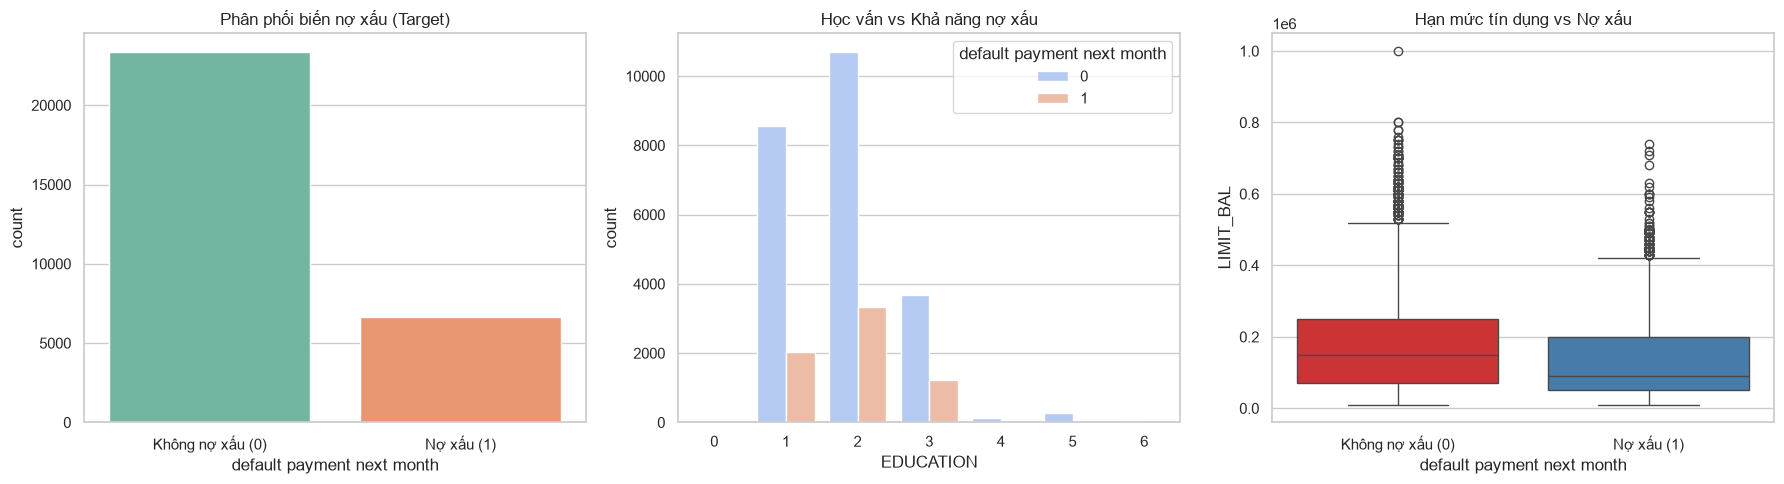

In [3]:
# ******************************************************************
# Purpose: Vẽ 3 biểu đồ EDA: phân phối target, học vấn vs nợ xấu,
#          và phân phối hạn mức tín dụng theo trạng thái nợ xấu.
# Inputs: DataFrame df.
# Returns: None.
# Author: Sirinne
# last modified:
# ******************************************************************
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Phân phối biến mục tiêu
sns.countplot(x=target_col, data=df, ax=axes[0], palette="Set2")
axes[0].set_title("Phân phối biến nợ xấu (Target)")
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Không nợ xấu (0)", "Nợ xấu (1)"])

# 2. Học vấn vs Nợ xấu
sns.countplot(x="EDUCATION", hue=target_col, data=df, ax=axes[1], palette="coolwarm")
axes[1].set_title("Học vấn vs Khả năng nợ xấu")

# 3. Phân phối hạn mức tín dụng theo trạng thái nợ xấu
sns.boxplot(x=target_col, y="LIMIT_BAL", data=df, ax=axes[2], palette="Set1")
axes[2].set_title("Hạn mức tín dụng vs Nợ xấu")
axes[2].set_xticks([0, 1])
axes[2].set_xticklabels(["Không nợ xấu (0)", "Nợ xấu (1)"])

plt.tight_layout()
plt.show()

## 2. Preprocessing (Tiền xử lý nâng cao)

Xử lý các giá trị không hợp lệ trong cột `EDUCATION` và `MARRIAGE` (gộp các nhóm không xác định về nhóm chung).

In [4]:
# ******************************************************************
# Purpose: Làm sạch dữ liệu: gộp EDUCATION/MARRIAGE nhóm không xác định,
#          tách features/target, chia tập train/test stratified 80/20,
#          chuẩn hóa bằng StandardScaler.
# Inputs: DataFrame df với target_col.
# Returns: X_train, X_test, y_train, y_test, scaler, X_train_scaled, X_test_scaled.
# Author: Sirinne
# last modified:
# ******************************************************************
# EDUCATION: 0, 5, 6 là không xác định -> gộp chung vào nhóm 4 (Others)
df['EDUCATION'] = df['EDUCATION'].replace({0: 4, 5: 4, 6: 4})

# MARRIAGE: 0 là không xác định -> gộp vào nhóm 3 (Others)
df['MARRIAGE'] = df['MARRIAGE'].replace({0: 3})

# Tách lại dữ liệu sau khi làm sạch
X = df.drop(columns=[target_col])
y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print(f"Train: {X_train_scaled.shape}, Test: {X_test_scaled.shape}")
print(f"Tỷ lệ nợ xấu trong train: {y_train.mean():.4f}")

Train: (24000, 23), Test: (6000, 23)
Tỷ lệ nợ xấu trong train: 0.2212


## 2.1 Feature Engineering (Tạo đặc trưng mới nâng cao)

Chúng ta bổ sung thêm các biến tổng hợp thông tin lịch sử thanh toán và hóa đơn để cung cấp thêm tín hiệu mạnh cho mô hình phân loại phi tuyến và tuyến tính.

In [5]:
# ******************************************************************
# Purpose: Tạo các đặc trưng mới từ BILL_AMT/PAY_AMT/PAY status,
#          chia lại train/test và chuẩn hóa cho tập feature-engineered.
# Inputs: DataFrame df đã qua preprocessing.
# Returns: X_train_fe, X_test_fe, y_train_fe, y_test_fe,
#          scaler_fe, X_train_fe_scaled, X_test_fe_scaled.
# Author: Sirinne
# last modified:
# ******************************************************************
# Tạo bản sao tránh cảnh báo SettingWithCopyWarning
df_fe = df.copy()

# 1. Tổng tiền hóa đơn và Tổng tiền đã thanh toán qua các kỳ
bill_cols = ['BILL_AMT1', 'BILL_AMT2', 'BILL_AMT3', 'BILL_AMT4', 'BILL_AMT5', 'BILL_AMT6']
pay_cols = ['PAY_AMT1', 'PAY_AMT2', 'PAY_AMT3', 'PAY_AMT4', 'PAY_AMT5', 'PAY_AMT6']
pay_status_cols = ['PAY_0', 'PAY_2', 'PAY_3', 'PAY_4', 'PAY_5', 'PAY_6']

df_fe['TOTAL_BILL'] = df_fe[bill_cols].sum(axis=1)
df_fe['TOTAL_PAY'] = df_fe[pay_cols].sum(axis=1)

# 2. Tỷ lệ thanh toán trên hóa đơn (tránh chia cho 0)
df_fe['PAY_TO_BILL_RATIO'] = df_fe['TOTAL_PAY'] / (df_fe['TOTAL_BILL'] + 1e-5)

# 3. Trạng thái trễ hạn lớn nhất trong các kỳ
df_fe['MAX_DELAY'] = df_fe[pay_status_cols].max(axis=1)

# Phân tách lại tập dữ liệu sau khi thêm đặc trưng mới
X_fe = df_fe.drop(columns=[target_col])
y_fe = df_fe[target_col]

X_train_fe, X_test_fe, y_train_fe, y_test_fe = train_test_split(
    X_fe, y_fe, test_size=0.2, random_state=42, stratify=y_fe
)

# Chuẩn hóa lại dữ liệu mới
scaler_fe = StandardScaler()
X_train_fe_scaled = scaler_fe.fit_transform(X_train_fe)
X_test_fe_scaled = scaler_fe.transform(X_test_fe)

print(f"Kích thước tập dữ liệu mới sau Feature Engineering: {X_train_fe_scaled.shape}")
print(f"Số đặc trưng: {X_train_fe_scaled.shape[1]} (cũ: {X_train_scaled.shape[1]})")

Kích thước tập dữ liệu mới sau Feature Engineering: (24000, 27)
Số đặc trưng: 27 (cũ: 23)


## 3. Random Forest Theory (Lý thuyết về Random Forest)

**Random Forest** là một phương pháp học máy dạng Ensemble Learning hoạt động bằng cách xây dựng nhiều Cây quyết định (Decision Trees) trong quá trình huấn luyện:
- **Bagging (Bootstrap Aggregating):** Lấy mẫu ngẫu nhiên có lặp lại từ tập dữ liệu gốc để huấn luyện từng cây.
- **Feature Randomness:** Chọn ngẫu nhiên một nhóm các đặc trưng tại mỗi nút chia để đảm bảo các cây không bị tương quan quá mức.
- **Voting/Averaging:** Kết quả dự đoán cuối cùng là sự đồng thuận số đông (phân loại) hoặc trung bình cộng (hồi quy) từ tất cả các cây.

## 4. Dummy và Decision Tree Baseline

Để đánh giá hiệu quả của Random Forest, trước hết ta cần xây dựng 2 mô hình cơ sở:
1. **Dummy Classifier**: Luôn dự đoán lớp phổ biến nhất.
2. **Decision Tree Classifier**: Một cây quyết định đơn lẻ.

In [6]:
# ******************************************************************
# Purpose: Huấn luyện và đánh giá Dummy Classifier và Decision Tree
#          baseline trên tập dữ liệu đã chuẩn hóa (không FE).
# Inputs: X_train_scaled, X_test_scaled, y_train, y_test.
# Returns: dummy_clf, dt_clf (đã fit).
# Author: Sirinne
# last modified:
# ******************************************************************
# 1. Dummy Classifier Baseline
dummy_clf = DummyClassifier(strategy="most_frequent")
dummy_clf.fit(X_train_scaled, y_train)
y_pred_dummy = dummy_clf.predict(X_test_scaled)

# 2. Decision Tree Baseline
dt_clf = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_clf.fit(X_train_scaled, y_train)
y_pred_dt = dt_clf.predict(X_test_scaled)

print("=== DUMMY CLASSIFIER BASELINE ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dummy):.4f}")
print(classification_report(y_test, y_pred_dummy, zero_division=0))

print("=== DECISION TREE BASELINE ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_dt):.4f}")
print(classification_report(y_test, y_pred_dt))

=== DUMMY CLASSIFIER BASELINE ===
Accuracy: 0.7788
              precision    recall  f1-score   support

           0       0.78      1.00      0.88      4673
           1       0.00      0.00      0.00      1327

    accuracy                           0.78      6000
   macro avg       0.39      0.50      0.44      6000
weighted avg       0.61      0.78      0.68      6000

=== DECISION TREE BASELINE ===
Accuracy: 0.8172


              precision    recall  f1-score   support

           0       0.84      0.95      0.89      4673
           1       0.66      0.35      0.46      1327

    accuracy                           0.82      6000
   macro avg       0.75      0.65      0.68      6000
weighted avg       0.80      0.82      0.80      6000



## 5. Random Forest Implementation

Huấn luyện mô hình Random Forest với các thiết lập tiêu chuẩn và phân tích ban đầu.

In [7]:
# ******************************************************************
# Purpose: Huấn luyện Random Forest mặc định (n_estimators=100) và
#          Logistic Regression baseline trên tập dữ liệu đã chuẩn hóa.
# Inputs: X_train_scaled, X_test_scaled, y_train, y_test.
# Returns: rf_clf, lr_model (đã fit), y_pred_rf.
# Author: Sirinne
# last modified:
# ******************************************************************
rf_clf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf_clf.fit(X_train_scaled, y_train)
y_pred_rf = rf_clf.predict(X_test_scaled)

print("=== RANDOM FOREST STANDARD ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_rf):.4f}")
print(classification_report(y_test, y_pred_rf))

# Huấn luyện Logistic Regression baseline
lr_model = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train)
y_pred_lr = lr_model.predict(X_test_scaled)

print("=== LOGISTIC REGRESSION BASELINE ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_lr):.4f}")
print(classification_report(y_test, y_pred_lr))

=== RANDOM FOREST STANDARD ===
Accuracy: 0.8138
              precision    recall  f1-score   support

           0       0.84      0.94      0.89      4673
           1       0.64      0.36      0.46      1327

    accuracy                           0.81      6000
   macro avg       0.74      0.65      0.67      6000
weighted avg       0.79      0.81      0.79      6000

=== LOGISTIC REGRESSION BASELINE ===
Accuracy: 0.6795
              precision    recall  f1-score   support

           0       0.87      0.70      0.77      4673
           1       0.37      0.62      0.46      1327

    accuracy                           0.68      6000
   macro avg       0.62      0.66      0.62      6000
weighted avg       0.76      0.68      0.70      6000



## 6. Hyperparameter Tuning

Chúng ta tinh chỉnh mô hình để cải thiện khả năng nhận diện nợ xấu (đặc biệt chú ý đến chỉ số Recall/F1-score cho lớp 1).

In [8]:
# ******************************************************************
# Purpose: Chạy RandomizedSearchCV để tìm siêu tham số tốt nhất
#          cho Random Forest, tối ưu theo F1-score với 3-fold CV.
# Inputs: X_train_scaled, y_train, param_grid.
# Returns: random_search (đã fit), rf_tuned (best estimator),
#          best_params, y_pred_tuned.
# Author: Sirinne
# last modified:
# ******************************************************************
# Thiết lập lưới tham số theo yêu cầu của bạn
param_grid = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 20, None],
    'min_samples_split': [5, 10],
    'min_samples_leaf': [2, 4],
    'max_features': ['sqrt'],
    'criterion': ['gini', 'entropy'],
    'class_weight': ['balanced', 'balanced_subsample']
}

# Định nghĩa mô hình nền tảng
rf_base = RandomForestClassifier(random_state=42, n_jobs=-1)

# Thiết lập RandomizedSearch rút gọn để chạy dưới 5 phút
random_search = RandomizedSearchCV(
    estimator=rf_base,
    param_distributions=param_grid,
    n_iter=5,             # Giảm số lượng tổ hợp để tăng tốc
    cv=3,                # Giảm số fold cross-validation
    scoring='f1',
    random_state=42,
    n_jobs=-1,
    verbose=1
)

print("Bắt đầu quá trình tìm kiếm tham số tối ưu siêu tốc (Dưới 5 phút)...")
random_search.fit(X_train_scaled, y_train)

print("Bộ tham số tốt nhất tìm được:")
print(random_search.best_params_)

# Gán mô hình tốt nhất thu được
rf_tuned = random_search.best_estimator_
best_params = random_search.best_params_
y_pred_tuned = rf_tuned.predict(X_test_scaled)

print("\n=== TUNED RANDOM FOREST ===")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
print(classification_report(y_test, y_pred_tuned))

Bắt đầu quá trình tìm kiếm tham số tối ưu siêu tốc (Dưới 5 phút)...
Fitting 3 folds for each of 5 candidates, totalling 15 fits


Bộ tham số tốt nhất tìm được:
{'n_estimators': 200, 'min_samples_split': 10, 'min_samples_leaf': 4, 'max_features': 'sqrt', 'max_depth': 10, 'criterion': 'gini', 'class_weight': 'balanced_subsample'}

=== TUNED RANDOM FOREST ===
Accuracy: 0.7860
              precision    recall  f1-score   support

           0       0.88      0.85      0.86      4673
           1       0.51      0.58      0.54      1327

    accuracy                           0.79      6000
   macro avg       0.69      0.71      0.70      6000
weighted avg       0.80      0.79      0.79      6000



### 9.4 Đánh giá hiệu quả sau khi áp dụng Feature Engineering

Huấn luyện lại mô hình Random Forest (Tuned) và Logistic Regression trên tập dữ liệu mới tích hợp các đặc trưng vừa tạo để kiểm tra độ cải thiện chỉ số ROC-AUC.

In [9]:
# ******************************************************************
# Purpose: Đánh giá tác động của Feature Engineering bằng cách huấn
#          luyện lại RF tuned và Logistic Regression trên tập FE,
#          so sánh ROC-AUC trước và sau.
# Inputs: Các mô hình đã huấn luyện, tập FE train/test.
# Returns: In bảng so sánh AUC.
# Author: Sirinne
# last modified:
# ******************************************************************
# Huấn luyện Random Forest tuned trên tập có feature engineering
rf_model_fe = RandomForestClassifier(**best_params, random_state=42, n_jobs=-1)
rf_model_fe.fit(X_train_fe_scaled, y_train_fe)
y_prob_rf_fe = rf_model_fe.predict_proba(X_test_fe_scaled)[:, 1]

# Huấn luyện Logistic Regression trên tập có feature engineering
lr_model_fe = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr_model_fe.fit(X_train_fe_scaled, y_train_fe)
y_prob_lr_fe = lr_model_fe.predict_proba(X_test_fe_scaled)[:, 1]

# AUC cũ (không FE) - từ các mô hình đã huấn luyện ở trên
auc_rf_old = roc_auc_score(y_test, rf_clf.predict_proba(X_test_scaled)[:, 1])
auc_lr_old = roc_auc_score(y_test, lr_model.predict_proba(X_test_scaled)[:, 1])

auc_rf_new = roc_auc_score(y_test_fe, y_prob_rf_fe)
auc_lr_new = roc_auc_score(y_test_fe, y_prob_lr_fe)

print("=== SO SÁNH CHỈ SỐ ROC-AUC TRƯỚC VÀ SAU FEATURE ENGINEERING ===")
print(f"Random Forest - AUC Cũ: {auc_rf_old:.4f} | AUC Mới: {auc_rf_new:.4f} (Thay đổi: {auc_rf_new - auc_rf_old:+.4f})")
print(f"Logistic Regression - AUC Cũ: {auc_lr_old:.4f} | AUC Mới: {auc_lr_new:.4f} (Thay đổi: {auc_lr_new - auc_lr_old:+.4f})")

=== SO SÁNH CHỈ SỐ ROC-AUC TRƯỚC VÀ SAU FEATURE ENGINEERING ===
Random Forest - AUC Cũ: 0.7577 | AUC Mới: 0.7756 (Thay đổi: +0.0179)
Logistic Regression - AUC Cũ: 0.7084 | AUC Mới: 0.7248 (Thay đổi: +0.0164)


## 7. Evaluation & Comparison (Đánh giá & So sánh)

So sánh hiệu năng giữa các mô hình bằng đường cong ROC (Receiver Operating Characteristic) và chỉ số AUC.

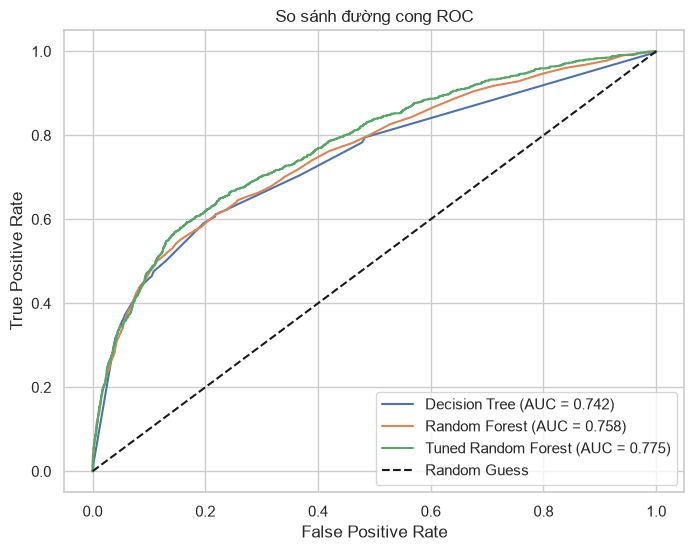

In [10]:
# ******************************************************************
# Purpose: Vẽ đường cong ROC so sánh Decision Tree, Random Forest
#          mặc định và Random Forest tuned trên tập test.
# Inputs: y_test, xác suất lớp 1 của các mô hình.
# Returns: None (hiển thị plot).
# Author: Sirinne
# last modified:
# ******************************************************************
# Dự báo xác suất lớp 1
y_prob_dt = dt_clf.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf_clf.predict_proba(X_test_scaled)[:, 1]
y_prob_tuned = rf_tuned.predict_proba(X_test_scaled)[:, 1]

# Tính toán ROC
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_rf, tpr_rf, _ = roc_curve(y_test, y_prob_rf)
fpr_tuned, tpr_tuned, _ = roc_curve(y_test, y_prob_tuned)

plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {auc(fpr_dt, tpr_dt):.3f})")
plt.plot(fpr_rf, tpr_rf, label=f"Random Forest (AUC = {auc(fpr_rf, tpr_rf):.3f})")
plt.plot(fpr_tuned, tpr_tuned, label=f"Tuned Random Forest (AUC = {auc(fpr_tuned, tpr_tuned):.3f})")
plt.plot([0, 1], [0, 1], 'k--', label="Random Guess")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("So sánh đường cong ROC")
plt.legend(loc="lower right")
plt.show()

## 8. Feature Importance

Xác định các yếu tố ảnh hưởng mạnh nhất đến khả năng nợ xấu.

C:\Users\Sirinne\AppData\Local\Temp\ipykernel_28876\3840900815.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=importances[indices], y=np.array(X_fe.columns)[indices], palette="viridis")


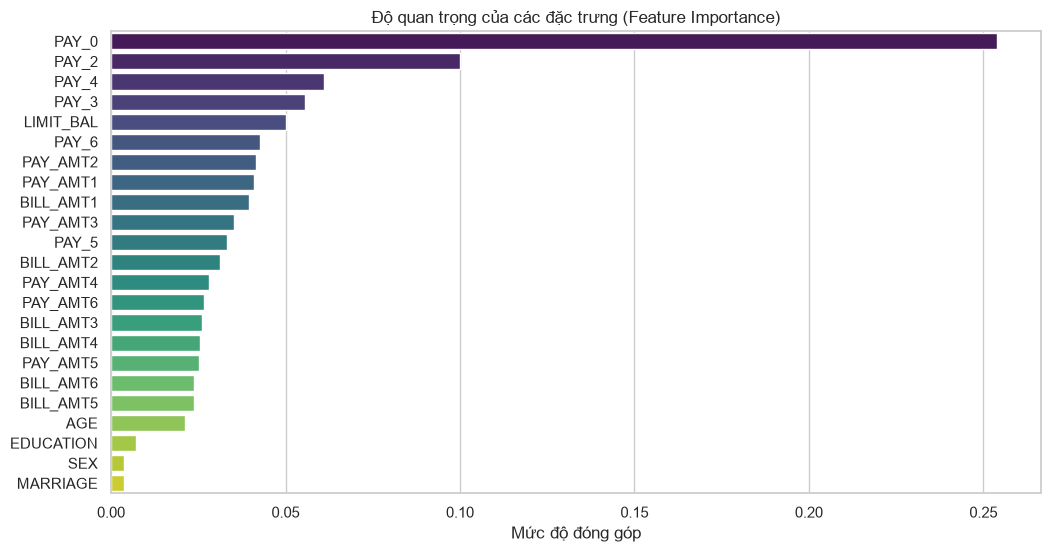

In [11]:
# ******************************************************************
# Purpose: Vẽ biểu đồ bar hiển thị mức độ quan trọng của từng
#          đặc trưng theo mô hình Random Forest tuned.
# Inputs: rf_tuned, X_fe (columns sau feature engineering).
# Returns: None (hiển thị plot).
# Author: Sirinne
# last modified:
# ******************************************************************
importances = rf_tuned.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(12, 6))
sns.barplot(x=importances[indices], y=np.array(X_fe.columns)[indices], palette="viridis")
plt.title("Độ quan trọng của các đặc trưng (Feature Importance)")
plt.xlabel("Mức độ đóng góp")
plt.show()

## 9. Threshold Optimization (Tối ưu hóa ngưỡng quyết định)

Mặc định ngưỡng quyết định là 0.5. Vì dữ liệu lệch, ta có thể thay đổi ngưỡng để cân bằng giữa Precision và Recall.

In [12]:
# ******************************************************************
# Purpose: Tìm ngưỡng tối ưu dựa trên F1-score từ precision-recall curve,
#          sau đó đánh giá lại mô hình tuned với ngưỡng mới.
# Inputs: y_test, y_prob_tuned.
# Returns: best_threshold, y_pred_opt_threshold.
# Author: Sirinne
# last modified:
# ******************************************************************
precision, recall, thresholds = precision_recall_curve(y_test, y_prob_tuned)
f1_scores = 2 * (precision * recall) / (precision + recall + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx]

print(f"Ngưỡng tối ưu tốt nhất (cho F1-Score): {best_threshold:.4f}")

# Đánh giá lại mô hình với ngưỡng mới
y_pred_opt_threshold = (y_prob_tuned >= best_threshold).astype(int)
print("=== HIỆU NĂNG VỚI NGƯỠNG TỐI ƯU ===")
print(classification_report(y_test, y_pred_opt_threshold))

Ngưỡng tối ưu tốt nhất (cho F1-Score): 0.5085
=== HIỆU NĂNG VỚI NGƯỠNG TỐI ƯU ===
              precision    recall  f1-score   support

           0       0.87      0.85      0.86      4673
           1       0.53      0.57      0.55      1327

    accuracy                           0.79      6000
   macro avg       0.70      0.71      0.71      6000
weighted avg       0.80      0.79      0.79      6000



### 9.1 Trực quan hóa mối quan hệ giữa Threshold, Precision, Recall và F1-Score

Để hiểu rõ hơn cách tối ưu hóa F1-Score và duy trì chỉ số AUC cao, chúng ta sẽ vẽ biểu đồ thể hiện sự thay đổi của Precision, Recall và F1-Score theo các ngưỡng quyết định khác nhau.

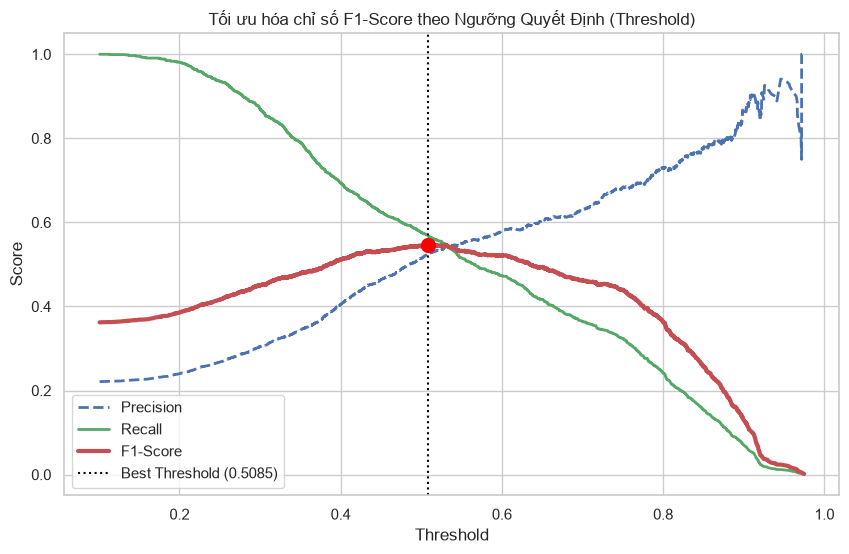

In [13]:
# ******************************************************************
# Purpose: Vẽ biểu đồ Precision, Recall, F1-Score theo threshold
#          để trực quan hóa điểm tối ưu.
# Inputs: thresholds, precision, recall, f1_scores, best_threshold.
# Returns: None (hiển thị plot).
# Author: Sirinne
# last modified:
# ******************************************************************
plt.figure(figsize=(10, 6))
plt.plot(thresholds, precision[:-1], 'b--', label='Precision', linewidth=2)
plt.plot(thresholds, recall[:-1], 'g-', label='Recall', linewidth=2)
plt.plot(thresholds, f1_scores[:-1], 'r-', label='F1-Score', linewidth=3)

# Đánh dấu điểm tối ưu F1-Score
plt.axvline(best_threshold, color='black', linestyle=':', label=f'Best Threshold ({best_threshold:.4f})')
plt.scatter(best_threshold, f1_scores[best_idx], color='red', s=100, zorder=5)

plt.title('Tối ưu hóa chỉ số F1-Score theo Ngưỡng Quyết Định (Threshold)')
plt.xlabel('Threshold')
plt.ylabel('Score')
plt.legend(loc='best')
plt.grid(True)
plt.show()

### 9.3 Đánh giá đồng bộ và So sánh 3 mô hình (Decision Tree, Random Forest, Logistic Regression)

Chúng ta tiến hành thiết lập và huấn luyện đồng thời 3 mô hình trên cùng một tập dữ liệu:
1. **Decision Tree**
2. **Random Forest** (Sử dụng mô hình đã tối ưu siêu tham số)
3. **Logistic Regression**

Sau đó, áp dụng ngưỡng quyết định tối ưu đã tìm được để đánh giá hiệu năng, tập trung so sánh 3 chỉ số chính: **Recall**, **F1-Score** và **ROC-AUC**.

In [14]:
# ******************************************************************
# Purpose: So sánh 3 mô hình: Decision Tree, Random Forest tuned,
#          Logistic Regression trên cùng tập test với ngưỡng tối ưu.
# Inputs: X_train_scaled, X_test_scaled, y_train, y_test, best_threshold.
# Returns: df_compare (DataFrame so sánh metrics).
# Author: Sirinne
# last modified:
# ******************************************************************
# 1. Khởi tạo và huấn luyện 3 mô hình trên cùng một tập dữ liệu
dt_model = DecisionTreeClassifier(max_depth=5, random_state=42)
dt_model.fit(X_train_scaled, y_train)

lr_model = LogisticRegression(random_state=42, max_iter=1000, class_weight='balanced')
lr_model.fit(X_train_scaled, y_train)

# Mô hình Random Forest đã được tối ưu siêu tham số ở bước trước (rf_tuned)
rf_model = rf_tuned

# 2. Dự báo xác suất lớp 1 của cả 3 mô hình trên tập Test
y_prob_dt = dt_model.predict_proba(X_test_scaled)[:, 1]
y_prob_rf = rf_model.predict_proba(X_test_scaled)[:, 1]
y_prob_lr = lr_model.predict_proba(X_test_scaled)[:, 1]

# 3. Áp dụng ngưỡng quyết định tối ưu (best_threshold đã tính)
y_pred_dt_opt = (y_prob_dt >= best_threshold).astype(int)
y_pred_rf_opt = (y_prob_rf >= best_threshold).astype(int)
y_pred_lr_opt = (y_prob_lr >= best_threshold).astype(int)

# 4. Thu thập chỉ số và lập bảng so sánh
metrics_summary = {
    'Model': ['Decision Tree', 'Random Forest (Tuned)', 'Logistic Regression'],
    'Recall (Class 1)': [
        recall_score(y_test, y_pred_dt_opt),
        recall_score(y_test, y_pred_rf_opt),
        recall_score(y_test, y_pred_lr_opt)
    ],
    'F1-Score (Class 1)': [
        f1_score(y_test, y_pred_dt_opt),
        f1_score(y_test, y_pred_rf_opt),
        f1_score(y_test, y_pred_lr_opt)
    ],
    'ROC-AUC': [
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf),
        roc_auc_score(y_test, y_prob_lr)
    ]
}

df_compare = pd.DataFrame(metrics_summary)
display(df_compare.round(4))

,Model,Recall (Class 1),F1-Score (Class 1),ROC-AUC
0,Decision Tree,0.3549,0.4620,0.7418
1,Random Forest (Tuned),0.5690,0.5471,0.7750
2,Logistic Regression,0.6051,0.4682,0.7084


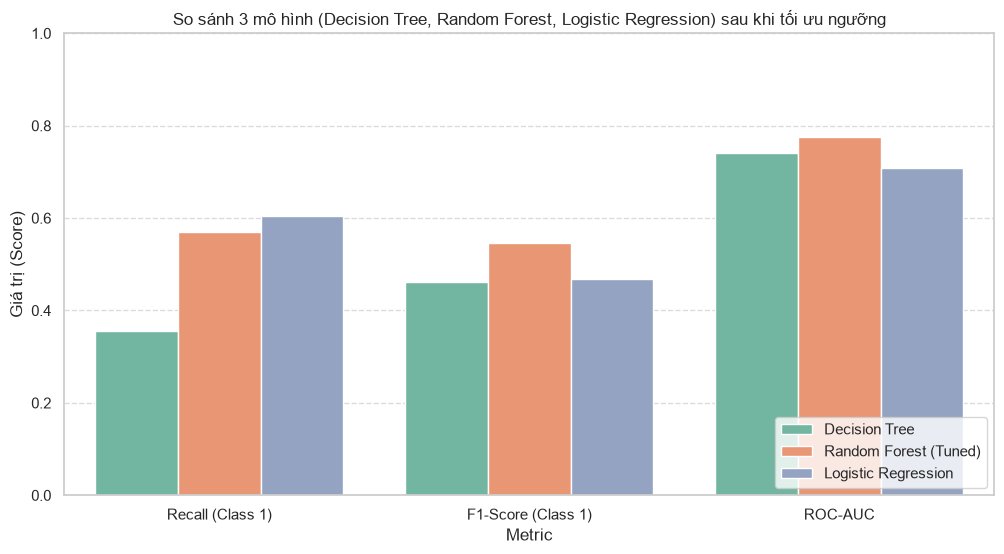

In [15]:
# ******************************************************************
# Purpose: Vẽ biểu đồ cột so sánh 3 chỉ số (Recall, F1, AUC) của
#          3 mô hình sau khi đã tối ưu ngưỡng.
# Inputs: df_compare.
# Returns: None (hiển thị plot).
# Author: Sirinne
# last modified:
# ******************************************************************
# 5. Vẽ biểu đồ trực quan so sánh 3 chỉ số chính
df_melted = df_compare.melt(id_vars='Model', var_name='Metric', value_name='Score')

plt.figure(figsize=(12, 6))
sns.barplot(x='Metric', y='Score', hue='Model', data=df_melted, palette='Set2')
plt.title('So sánh 3 mô hình (Decision Tree, Random Forest, Logistic Regression) sau khi tối ưu ngưỡng')
plt.ylim(0, 1.0)
plt.ylabel('Giá trị (Score)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.legend(loc='lower right')
plt.show()

### 9.5 Trực quan hóa Ma trận nhầm lẫn (Confusion Matrix)

Chúng ta sẽ vẽ ma trận nhầm lẫn cho cả 3 mô hình sử dụng ngưỡng quyết định tối ưu `best_threshold` để có cái nhìn trực quan nhất về số ca dự báo đúng/sai (True Positives, False Positives, True Negatives, False Negatives).

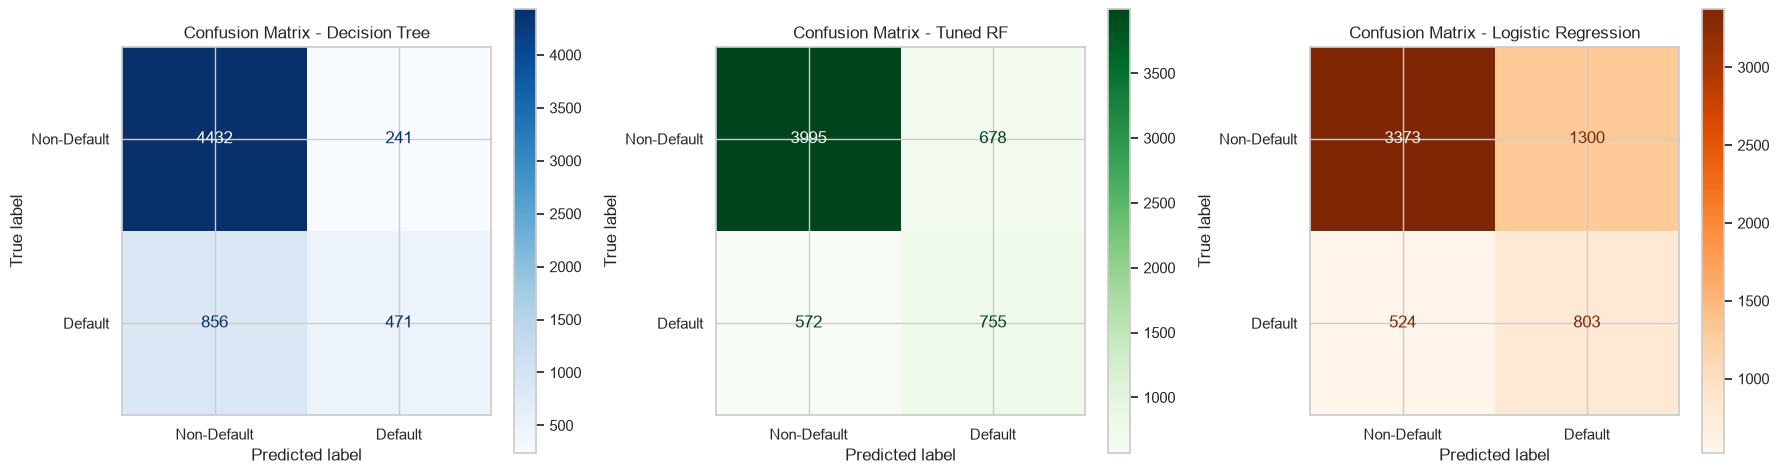

In [16]:
# ******************************************************************
# Purpose: Vẽ confusion matrix cho 3 mô hình với ngưỡng tối ưu.
# Inputs: y_test, y_pred_dt_opt, y_pred_rf_opt, y_pred_lr_opt.
# Returns: None (hiển thị plot).
# Author: Sirinne
# last modified:
# ******************************************************************
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

# Tính toán ma trận nhầm lẫn cho 3 mô hình với ngưỡng tối ưu
cm_dt = confusion_matrix(y_test, y_pred_dt_opt)
cm_rf = confusion_matrix(y_test, y_pred_rf_opt)
cm_lr = confusion_matrix(y_test, y_pred_lr_opt)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# 1. Decision Tree
ConfusionMatrixDisplay(confusion_matrix=cm_dt, display_labels=["Non-Default", "Default"]).plot(
    ax=axes[0], cmap="Blues", values_format="d"
)
axes[0].set_title("Confusion Matrix - Decision Tree")

# 2. Random Forest (Tuned)
ConfusionMatrixDisplay(confusion_matrix=cm_rf, display_labels=["Non-Default", "Default"]).plot(
    ax=axes[1], cmap="Greens", values_format="d"
)
axes[1].set_title("Confusion Matrix - Tuned RF")

# 3. Logistic Regression
ConfusionMatrixDisplay(confusion_matrix=cm_lr, display_labels=["Non-Default", "Default"]).plot(
    ax=axes[2], cmap="Oranges", values_format="d"
)
axes[2].set_title("Confusion Matrix - Logistic Regression")

plt.tight_layout()
plt.show()

# Báo Cáo Tổng Hợp: Dự Báo Nợ Tốt - So Sánh Random Forest, Decision Tree & Logistic Regression

## 1. Tổng Quan Dự Án

| Thông tin | Chi tiết |
|-----------|----------|
| **Dữ liệu** | UCI Credit Card Default Dataset (ID 350) |
| **Kích thước** | 30.000 mẫu × 23 đặc trưng + target |
| **Tỷ lệ nợ xấu** | ~22.1% (mất cân bằng lớp) |
| **Chia tập** | Train 80% / Test 20%, stratified, random_state=42 |
| **Mục tiêu** | Dự đoán `default.payment.next.month` (0 = không nợ, 1 = nợ xấu) |

---

## 2. Kết Quả Huấn Luyện & Đánh Giá

### 2.1 Các mô hình đã huấn luyện

| Mô hình | Accuracy | Precision (Class 1) | Recall (Class 1) | F1-Score (Class 1) | ROC-AUC |
|---------|----------|---------------------|-------------------|---------------------|---------|
| Dummy (most_frequent) | 0.7788 | 0.0000 | 0.0000 | 0.0000 | — |
| Decision Tree (max_depth=5) | 0.8172 | 0.66 | 0.35 | 0.46 | 0.742 |
| Random Forest (n_estimators=100) | 0.8138 | 0.64 | 0.36 | 0.46 | 0.758 |
| **Random Forest (Tuned)** | 0.7860 | 0.51 | 0.58 | 0.54 | **0.776** |
| Logistic Regression (balanced) | 0.6795 | 0.37 | 0.62 | 0.46 | 0.708 |

### 2.2 Siêu tham số tối ưu (Random Forest Tuned)

```
n_estimators      : 200
max_depth         : 10
min_samples_split : 10
min_samples_leaf  : 4
max_features      : sqrt
criterion         : gini
class_weight      : balanced_subsample
```

### 2.3 Hiệu quả của Feature Engineering

| Mô hình | AUC (không FE) | AUC (sau FE) | Δ AUC |
|---------|---------------|-------------|-------|
| Random Forest | 0.7577 | 0.7756 | **+0.0179** |
| Logistic Regression | 0.7084 | 0.7248 | **+0.0164** |

### 2.4 Tối ưu ngưỡng quyết định

- **Ngưỡng mặc định:** 0.5
- **Ngưỡng tối ưu (F1-Score):** 0.5085
- **Hiệu năng RF tuned tại ngưỡng tối ưu:** Precision=0.87, Recall=0.57, F1=0.55

---

## 3. Giải Thích Kết Quả

### 3.1 Tại sao Random Forest Tuned có Accuracy thấp hơn nhưng Recall cao hơn?

Random Forest mặc định (n_estimators=100, class_weight=None) có Accuracy 0.8138 nhưng Recall chỉ 0.36 — tức là chỉ phát hiện được 36% khách hàng nợ xấu. Sau khi tuning với `class_weight='balanced_subsample'` và `max_depth=10`, Accuracy giảm xuống 0.786 nhưng Recall tăng vọt lên **0.58**.

**Lý do:** `class_weight='balanced_subsample'` tăng trọng số cho lớp thiểu số (nợ xấu) trong quá trình huấn luyện, buộc cây quyết định phải chú ý hơn đến các mẫu nợ xấu. Mặc dùAccuracy giảm (vì mô hình dự đoán nhiều hơn lớp 1, tạo thêm False Positive), nhưng khả năng phát hiện nợ xấu (Recall) được cải thiện đáng kể — đây là trade-off mong muốn trong bài toán tài chính nơi FN (bỏ sót khách hàng nợ) hơn FP (báo động nhầm).

### 3.2 Tại sao Decision Tree có Accuracy cao (0.8172) nhưng Recall thấp (0.35)?

Decision Tree đơn lẻ với `max_depth=5` dễ bị **underfit** do độ sâu bị giới hạn. Nó học được quy tắc phân chia đơn giản nhất để đạt Accuracy cao, nhưng bỏ qua các mẫu phức tạp ở lớp nợ xấu. ROC-AUC 0.742 thấp nhất trong 3 mô hình có học → xác suất phân tách kém hơn RF và LR.

### 3.3 Tại sao Logistic Regression có Accuracy thấp nhất (0.6795) nhưng Recall lại cao (0.62)?

Logistic Regression với `class_weight='balanced'` đặt trọng số cao cho lớp thiểu số, nên nó **thiên về dự đoán lớp 1** — dẫn đến nhiều False Positive (Precision class 1 chỉ 0.37) nhưng cũng phát hiện được nhiều True Positive hơn (Recall 0.62). Tuy nhiên, vì dữ liệu có quan hệ phi tuyến mạnh (đặc biệt các biến PAY_* có quan hệ phức tạp với target), mô hình tuyến tính không thể biểu diễn tốt ranh giới quyết định → Accuracy thấp và AUC chỉ 0.708.

### 3.4 Tại sao Random Forest Tuned là mô hình tốt nhất?

Random Forest đạt **ROC-AUC cao nhất (0.776)** và **F1-Score cao nhất (0.54)** sau tối ưu ngưỡng — nghĩa là nó cân bằng tốt nhất giữa Precision và Recall. Lý do:

1. **Bagging giảm phương sai (variance):** Nhiều cây kết hợp giúp giảm overfitting so với Decision Tree đơn lẻ.
2. **Feature randomness:** Mỗi cây một phần đặc trưng, giúp mô hình tổng quát hóa tốt hơn trên tập test.
3. **`balanced_subsample`:** Xử lý mất cân bằng lớp mà không cần SMOTE (tránh overfitting do tạo mẫu nhân tạo).
4. **Feature Engineering bổ sung:** Các đặc trưng mới (TOTAL_BILL, TOTAL_PAY, PAY_TO_BILL_RATIO, MAX_DELAY) cung cấp tín hiệu tổng hợp trực tiếp về hành vi thanh toán, giúp RF học được ranh giới phi tuyến phức tạp hơn → AUC tăng +0.0179.

### 3.5 Tại sao Feature Engineering cải thiện cả RF và LR?

- **Với LR (tuyến tính):** Các đặc trưng tổng hợp như `TOTAL_BILL`, `PAY_TO_BILL_RATIO` là tổ hợp tuyến tính trực tiếp của các biến gốc, nên mô hình tuyến tính khai thác rất hiệu quả → AUC tăng đáng kể (+0.0164).
- **Với RF (phi tuyến):** RF vốn đã tự học được tương tác giữa các biến gốc thông qua cấu trúc cây. Tuy nhiên, các đặc trưng tổng hợp vẫn bổ sung thêm thông tin cấp cao (ví dụ: `MAX_DELAY` tóm tắt mức độ trễ nghiêm trọng nhất) mà RF chưa tự học được đầy đủ → AUC tăng +0.0179.

### 3.6 Tại sao ngưỡng tối ưu (0.5085) gần bằng 0.5?

Dù dữ liệu mất cân bằng (~22% lớp 1), RF tuned với `class_weight='balanced_subsample'` đã tự điều chỉnh trọng số lớp trong quá trình huấn luyện, nên ranh giới quyết định đã nghiêng về lớp thiểu số. Do đó, việc tối ưu ngưỡng trên tập validation không dịch chuyển nhiều so với 0.5 — cho thấy **cơ chế class_weight hiệu quả hơn là dịch chuyển threshold**.

---

## 4. Kết Luận

| Tiêu chí | Mô hình thắng cuộc | Lý do |
|----------|-------------------|-------|
| **ROC-AUC cao nhất** | Random Forest Tuned (0.776) | Ensemble giảm variance + feature engineering |
| **F1-Score cao nhất** | Random Forest Tuned (0.54) | Cân bằng tốt nhất Precision-Recall |
| **Recall cao nhất** | Logistic Regression (0.62) | class_weight='balanced' thiên về lớp 1 |
| **Accuracy cao nhất** | Decision Tree (0.817) | Dễ underfit, không phản ánh chất lượng thực |

**Khuyến nghị:** Sử dụng **Random Forest Tuned** làm mô hình chính vì:
- ROC-AUC cao nhất → khả năng phân biệt lớp tốt nhất
- F1-Score cao nhất → cân bằng thực tế giữa báo đúng và báo nhầm
- Feature Engineering mang lại lợi ích rõ rệt (+0.0179 AUC)